<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lesson 03 · Applied AI: unstructured data</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">02 · Tweet sentiment analysis</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">Can we beat the 83% of “always say positive”?</p>
</div>

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/03-applied-ai-projects/blob/main/01_text_mining/02_project_tweets/02_Tweet_Sentiment_Analysis.ipynb) [![Slides](https://img.shields.io/badge/slides-Lesson_03-ffd43b)](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tweets)

## 🎯 Objectives
By the end of this notebook you will be able to:

- **clean** a real text dataset (empty texts, duplicates, train/test leakage) and explain why each step matters;
- tell a story with **EDA** on text: class balance, lengths, the words and patterns of each class;
- score sentiment with **lexicons** (VADER, AFINN), word by word, including a simple **negation** rule;
- train and compare **six classic models** on TF-IDF (Naive Bayes, Logistic Regression, linear SVM, KNN, Random Forest, XGBoost) plus sentence **embeddings**, on one **leaderboard**;
- use **transformers**: a pretrained Twitter model out of the box, and a **fine-tuned DistilBERT**, and weigh **score vs cost**.

**⏱️ Duration:** ≈ 90 min · **📋 Prerequisites:** notebook 01 (bag of words, TF-IDF, `Pipeline` with text) · Lesson 02 (metrics, threshold, class imbalance) · **▶️ How to use:** run the cells in order. The whole notebook runs on a laptop CPU in a few minutes; the fine-tuning step is **precomputed** (switch `RUN_HEAVY = True` on a GPU, e.g. Colab, to run it live).

## 📑 Contents

1. [🧭 The question and the data](#sec-1)
2. [🧹 Cleaning: empty, duplicated and leaked tweets](#sec-2)
3. [🔎 EDA: what do negative tweets look like?](#sec-3)
4. [📖 Lexicons: sentiment from a dictionary](#sec-4)
5. [🤖 Classic machine learning on TF-IDF](#sec-5)
6. [🎚️ Class weights and thresholds: catching more negatives](#sec-6)
7. [🤗 Transformers: pretrained and fine-tuned](#sec-7)
8. [🔬 Error analysis: the tweets every model gets wrong](#sec-8)
9. [🏁 Final leaderboard: score vs cost](#sec-9)
10. [📌 Summary](#sec-10)
11. [📚 Learn more](#sec-11)

<a id="sec-0"></a>
## ⚙️ Setup

In [1]:
# ⚙️ Setup: works locally (VS Code / Jupyter) and in Google Colab
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/03-applied-ai-projects")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/the-ai-learning-hub/03-applied-ai-projects.git", str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "vaderSentiment", "wordcloud"], check=True)
else:  # locally: walk up until we find the folder that has src/ and data/
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())

sys.path.insert(0, str(ROOT))
print("Project root:", ROOT.name, "(Colab)" if IN_COLAB else "(local)")

Project root: 03-applied-ai-projects (local)


In [2]:
import json
import time
import warnings

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")   # keep the outputs short

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from huggingface_hub.utils import logging as hf_logging
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier

from src.paths import cache_dir, data_dir, models_dir
from src.plotting import CLASS_COLORS, MARKERS, PALETTE, apply_style, label_bars, leaderboard, save_fig
from src.text import (clean_tweet, evaluate, lexicon_predict, lexicon_score, load_lexicon, tokenize,
                      top_coefficients)

apply_style()
warnings.filterwarnings("ignore", category=FutureWarning)
transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()
hf_logging.set_verbosity_error()
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
pd.set_option("display.max_colwidth", 110)
RESULTS = ROOT / "01_text_mining" / "02_project_tweets" / "results"        # precomputed GPU results live next to this notebook

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE} · CPU threads: {torch.get_num_threads()}")

# Only the authors use this (EXPORT_SLIDES=1) to refresh the images in the slide deck.
EXPORT_SLIDES = os.environ.get("EXPORT_SLIDES") == "1"
def save_slide(fig, name):
    if EXPORT_SLIDES:
        save_fig(fig, ROOT / "assets" / "slides" / f"{name}.png")

Device: cpu · CPU threads: 8


> 🔁 **`RUN_HEAVY`**: fine-tuning a transformer takes ≈ 2 min on a GPU but ≈ 30+ min on a laptop CPU. With `RUN_HEAVY = False` (default) the notebook loads the results we computed on a GPU (`results/finetune_results.json`). In Colab choose *Runtime → Change runtime type → GPU* and set it to `True` to train it yourself.

In [3]:
RUN_HEAVY = False

<a id="sec-1"></a>
# 1. 🧭 The question and the data

Imagine you work for a brand. Thousands of tweets mention you every day and nobody can read them all. You want a model that flags the **negative** ones (an angry customer, a broken product) so that a human can answer quickly.

### 🗂️ Meet the data

| | |
|---|---|
| **What** | Short English tweets from 2009, labelled `pos` or `neg` |
| **Source** | Provided in the Text Mining course at ISCTE – University Institute of Lisbon |
| **Files** | `data/tweets/tweets_train.csv` (39,936 rows) · `data/tweets/tweets_test.csv` (9,985 rows) |
| **Columns** | `tweet` (id) · `text` (mentions already replaced by `USER`, links by `URL`) · `class` (`pos` / `neg`) |

More in the [data dictionary](../../data/DATA_DICTIONARY.md#english-tweets-with-sentiment-tweets).

In [4]:
train_raw = pd.read_csv(data_dir() / "tweets" / "tweets_train.csv")
test_raw = pd.read_csv(data_dir() / "tweets" / "tweets_test.csv")
print(f"train: {train_raw.shape} · test: {test_raw.shape}")
display(train_raw.sample(6, random_state=7))
print(train_raw["class"].value_counts(normalize=True).round(3).to_string())

train: (39936, 3) · test: (9985, 3)


,tweet,text,class
32997,1229673267,"Today's schedule: brunch, car wash, gift return, library, bookstore, home, dinner, and Scrabble. Long day ...",pos
35961,1229095157,Yes. Was landscape architect/land planner of huge real estate developments. 250k ac Got bored w 20 yrs ago...,pos
17379,1226623559,night. Oh I mention you in the HPR ep I'm editing now,pos
4454,1230181042,USPS won't let me schedule a carrier pickup. I should still have two hours to do so! I don't want to go ...,neg
5693,1228917488,listening to captain kirk butcher frank sinatra. good times,pos
34493,1230239528,I fell in our driveway today. I felt it coming so I sat down before I went totally down. Don't worry I'm o...,neg


class
pos    0.828
neg    0.172


About **83%** of the tweets are positive. So a "model" that **always says positive** is right 83% of the time, without reading a single word. That is our **baseline**, and the guiding question of this notebook: *can we beat it, and by how much?*

> ⚠️ **Accuracy is not enough here.** The always-positive model finds **zero** negative tweets, which is the only thing the brand cares about. We will compare models with three numbers (helper `evaluate` in `src/text.py`):
> - **macro-F1** (main score): the F1 of `pos` and the F1 of `neg`, averaged with the **same weight**. The lazy baseline gets ≈ 0.45.
> - **recall of `neg`**: the share of negative tweets the model catches.
> - **accuracy**, for reference.

<a id="sec-2"></a>
# 2. 🧹 Cleaning: empty, duplicated and leaked tweets

First we normalise the text with `clean_tweet` (in `src/text.py`): decode HTML entities (`&amp;` → `&`), turn links and `@names` into `URL` / `USER`, shorten letters repeated 3+ times (*"sooooo"* → *"soo"*), and lower-case everything except the two placeholders.

In [5]:
examples = ["@Anna I LOOOOVE this &amp; that!!! http://t.co/xyz",
            "USER Facebook is down. It's not you guys ",
            "Sorry I forgot my &lt;sarcasm&gt; tags."]
for e in examples:
    print(f"{e!r:60} →  {clean_tweet(e)!r}")

for df in (train_raw, test_raw):
    df["clean"] = df["text"].map(clean_tweet)

'@Anna I LOOOOVE this &amp; that!!! http://t.co/xyz'         →  'USER i loove this & that!!! URL'
"USER Facebook is down. It's not you guys "                  →  "USER facebook is down. it's not you guys"
'Sorry I forgot my &lt;sarcasm&gt; tags.'                    →  'sorry i forgot my <sarcasm> tags.'


Now three problems, each with its reason:

| Problem | Why it hurts |
|---|---|
| **Empty tweets** | Nothing to learn from; a model can only guess the majority class |
| **Duplicates inside train** | Some tweets count twice (and some even appear with **both** labels) |
| **Test tweets that are also in train** | **Leakage**: the model is tested on tweets it has memorised, so the score looks better than reality (Lesson 02!) |

In [6]:
def report(step, tr, te):
    return {"step": step, "train": len(tr), "test": len(te)}

log = [report("raw files", train_raw, test_raw)]

train = train_raw[train_raw["clean"] != ""]
test = test_raw[test_raw["clean"] != ""]
log.append(report("remove empty tweets", train, test))

conflicts = train.groupby("clean")["class"].nunique().gt(1).sum()
train = train.drop_duplicates("clean")
test = test.drop_duplicates("clean")
log.append(report("remove duplicated texts", train, test))

leaked = test["clean"].isin(set(train["clean"]))
test = test[~leaked]
log.append(report("remove test tweets seen in train", train, test))

train, test = train.reset_index(drop=True), test.reset_index(drop=True)
display(pd.DataFrame(log).set_index("step"))
print(f"{conflicts} train texts had BOTH labels · {leaked.sum()} test tweets were also in train (leakage)")

,train,test
step,,
raw files,39936,9985
remove empty tweets,39699,9925
remove duplicated texts,39152,9839
remove test tweets seen in train,39152,9687


18 train texts had BOTH labels · 152 test tweets were also in train (leakage)


In [7]:
test_raw.loc[test_raw["clean"].isin(set(train["clean"])) & (test_raw["clean"] != ""), ["text", "class"]].head(6)

,text,class
38,Working,neg
70,hee hee,pos
73,hope you feel better,pos
240,I'm sorry.,neg
305,"PLANNING FOR LAST SOUNDLESSONS OF 08 ON DEC. 27TH W/ J-ROCC (BEAT JUNKIES), ALOE BLACC & ME + ASYA'S B-DAY!",pos
398,Goodnight.,pos


Most leaked tweets are short and generic (*"good morning"*, *"thanks"*). Small numbers, but the habit matters: **the test set must contain only texts the model has never seen**. From now on we use `train` and `test` (clean).

<a id="sec-3"></a>
# 3. 🔎 EDA: what do negative tweets look like?

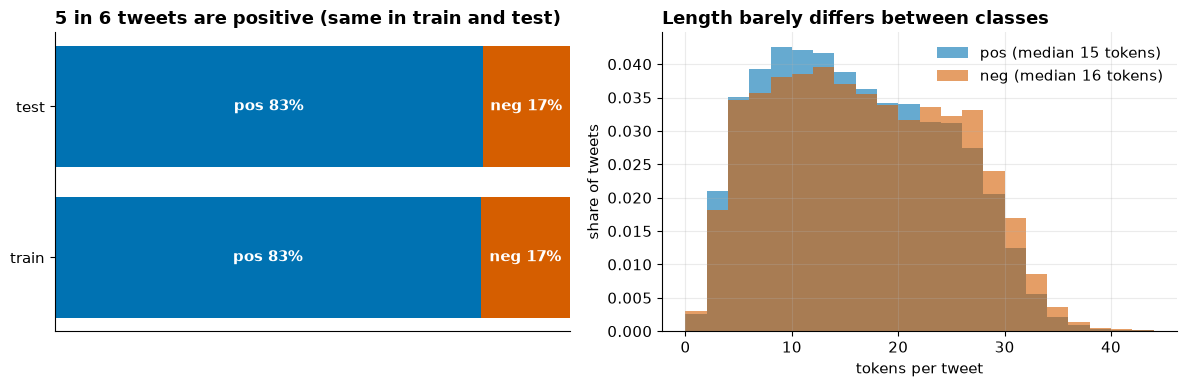

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
shares = pd.DataFrame({"train": train["class"].value_counts(normalize=True),
                       "test": test["class"].value_counts(normalize=True)}).T[["pos", "neg"]]
left = np.zeros(len(shares))
for label in ["pos", "neg"]:
    axes[0].barh(shares.index, shares[label], left=left, color=CLASS_COLORS[label], label=label)
    for i, v in enumerate(shares[label]):
        axes[0].text(left[i] + v / 2, i, f"{label} {v:.0%}", ha="center", va="center", color="white", fontweight="bold")
    left += shares[label].to_numpy()
axes[0].set(xlim=(0, 1), title="5 in 6 tweets are positive (same in train and test)")
axes[0].set_xticks([])
axes[0].grid(False)

n_words = train["clean"].map(lambda t: len(tokenize(t)))
bins = np.arange(0, 45, 2)
for label in ["pos", "neg"]:
    axes[1].hist(n_words[train["class"] == label], bins=bins, density=True, alpha=0.6, color=CLASS_COLORS[label],
                 label=f"{label} (median {n_words[train['class'] == label].median():.0f} tokens)")
axes[1].set(xlabel="tokens per tweet", ylabel="share of tweets", title="Length barely differs between classes")
axes[1].legend()
fig.tight_layout()
plt.show()

Length will not help much (unlike SMS spam). What about the **words**? Raw counts would show *the, I, to* for both classes. A better question: which words are **much more frequent in one class than in the other**? We compare the share of tweets that use each word (with a small +1 smoothing so rare words don't explode).

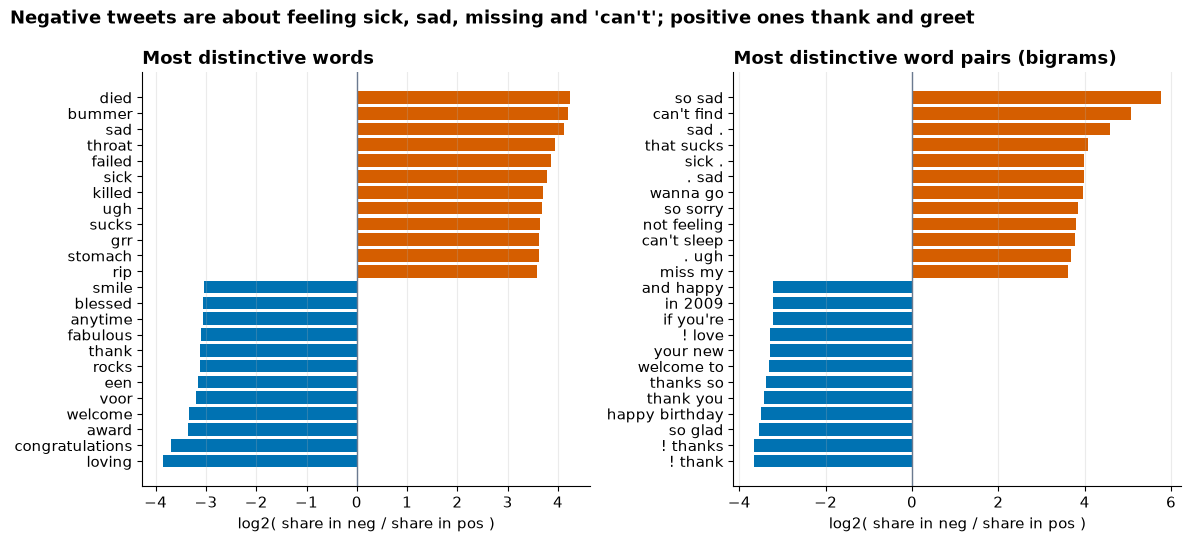

In [9]:
def distinctive_terms(texts, labels, ngram, n=12, min_df=20):
    """Terms whose frequency differs most between neg and pos (log2 ratio of smoothed shares)."""
    vec = CountVectorizer(tokenizer=tokenize, token_pattern=None, lowercase=False, ngram_range=(ngram, ngram),
                          min_df=min_df, binary=True)
    X = vec.fit_transform(texts)
    is_neg = (labels == "neg").to_numpy()
    share_neg = (np.asarray(X[is_neg].sum(axis=0)).ravel() + 1) / (is_neg.sum() + 2)
    share_pos = (np.asarray(X[~is_neg].sum(axis=0)).ravel() + 1) / ((~is_neg).sum() + 2)
    ratio = pd.Series(np.log2(share_neg / share_pos), index=vec.get_feature_names_out())
    ratio = ratio[~ratio.index.str.fullmatch(r"[!?.,; ]+")]        # skip punctuation-only terms
    return ratio.sort_values().head(n), ratio.sort_values().tail(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, ngram, name in zip(axes, [1, 2], ["words", "word pairs (bigrams)"]):
    pos_terms, neg_terms = distinctive_terms(train["clean"], train["class"], ngram)
    terms = pd.concat([pos_terms, neg_terms])
    ax.barh(terms.index, terms.values, color=[CLASS_COLORS["neg" if v > 0 else "pos"] for v in terms.values])
    ax.axvline(0, color=PALETTE["grey"], lw=1)
    ax.set(xlabel="log2( share in neg / share in pos )", title=f"Most distinctive {name}")
    ax.grid(axis="y", visible=False)
fig.suptitle("Negative tweets are about feeling sick, sad, missing and 'can't'; positive ones thank and greet",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()
save_slide(fig, "tm-distinctive-words")

A value of **+3** means "8× more frequent in negative tweets". The negative side is full of **feelings and problems** (sad, sick, miss, hurts, sucks) and **negations** (*can't*, *not*). The positive side greets and thanks. (Spot *een* and *voor*? A few tweets are in **Dutch**, and they happen to be labelled positive: a model will happily learn that "Dutch = happy". Datasets have quirks.) And twitter-specific **patterns**?

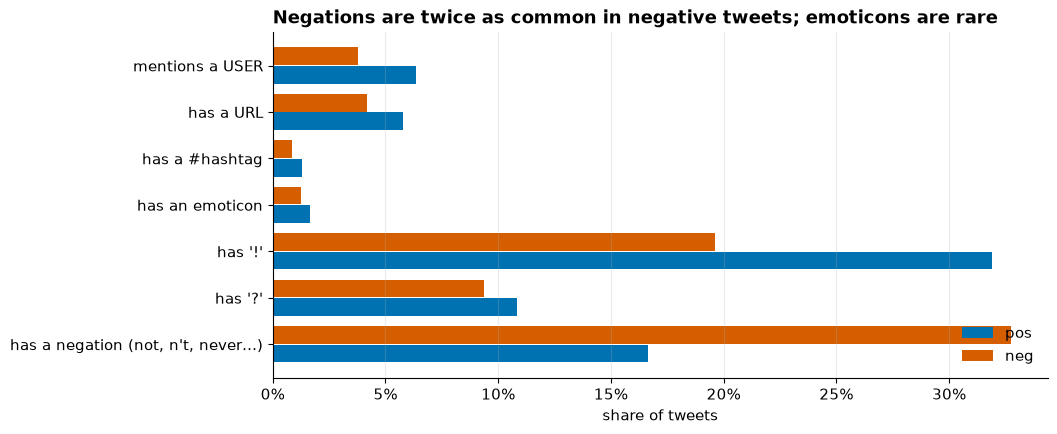

Emoticons: 1.7% of positive and 1.3% of negative tweets


class,pos,neg
mentions a USER,6.3%,3.8%
has a URL,5.8%,4.2%
has a #hashtag,1.3%,0.8%
has an emoticon,1.7%,1.3%
has '!',31.9%,19.6%
has '?',10.9%,9.4%
"has a negation (not, n't, never…)",16.6%,32.7%


In [10]:
patterns = {"mentions a USER": r"\bUSER\b", "has a URL": r"\bURL\b", "has a #hashtag": r"#\w+",
            "has an emoticon": r"[:;=]-?[()dDpP]", "has '!'": r"!", "has '?'": r"\?",
            "has a negation (not, n't, never…)": r"\b(?:not|no|never|cannot|cant|dont)\b|n't"}
table = pd.DataFrame({name: train.groupby("class")["clean"].apply(lambda s: s.str.contains(p).mean())
                      for name, p in patterns.items()}).T[["pos", "neg"]]

fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(table))
for k, label in enumerate(["pos", "neg"]):
    ax.barh(y + (0.2 if label == "pos" else -0.2), table[label], height=0.38, color=CLASS_COLORS[label], label=label)
ax.set_yticks(y, table.index)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set(xlabel="share of tweets", title="Negations are twice as common in negative tweets; emoticons are rare")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()
emo = table.loc["has an emoticon"]
print(f"Emoticons: {emo['pos']:.1%} of positive and {emo['neg']:.1%} of negative tweets")
table.style.format("{:.1%}")

Two surprises worth a discussion:

- **Negations** (*not*, *can't*, *don't*) appear in about **1 in 3** negative tweets and only 1 in 6 positive ones. Any good model has to handle them.
- **Emoticons are rare**: only about **1.7%** of positive and **1.3%** of negative tweets contain something that looks like one (see the table), which is strange for tweets. In famous datasets like *Sentiment140*, emoticons such as `:)` and `:(` were used to create the labels automatically and then **removed** so that models could not cheat. We don't know for sure how this dataset was labelled, but the missing emoticons (and the many tweets that end with a space) suggest something similar. 🕵️ Know your data!

Finally, one word cloud (just one!) for the negative class:

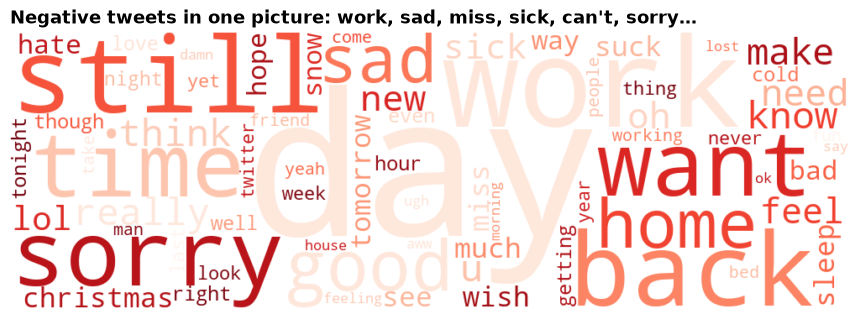

In [11]:
from wordcloud import STOPWORDS, WordCloud

neg_text = " ".join(train.loc[train["class"] == "neg", "clean"])
cloud = WordCloud(width=1000, height=330, background_color="white", colormap="Reds", random_state=SEED,
                  stopwords=STOPWORDS | {"USER", "URL", "im", "will", "got", "go", "going", "get", "now", "today", "one"},
                  max_words=70).generate(neg_text)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.imshow(cloud, interpolation="bilinear")
ax.axis("off")
ax.set_title("Negative tweets in one picture: work, sad, miss, sick, can't, sorry…")
plt.show()

### 🏆 The leaderboard starts
Every model we build goes into `board`. We start with the lazy baseline. The red dashed line in every leaderboard plot is its macro-F1.

In [12]:
board = {}   # name → {"family", "accuracy", "macro_f1", "recall_neg", "time_s", "timing"}

def add_to_board(name, y_pred, family, time_s=np.nan, timing="–"):
    """time_s = seconds for features + training + predicting the test set; timing = how it was measured."""
    board[name] = {"family": family, **evaluate(test["class"], y_pred), "time_s": time_s, "timing": timing}
    return pd.Series(board[name]).drop(["family", "timing"]).astype(float).round(3)

def show_board(highlight=None, title=None):
    scores = {name: row["macro_f1"] for name, row in board.items() if name != BASELINE}
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(scores) + 1.4))
    leaderboard(scores, baseline=board[BASELINE]["macro_f1"], metric="macro-F1 (test)", ax=ax,
                highlight=highlight, title=title)
    ax.set_xlim(0, 1)
    plt.show()
    return fig

BASELINE = "Always 'pos' (baseline)"
add_to_board(BASELINE, np.full(len(test), "pos"), "baseline")

accuracy      0.831
macro_f1      0.454
recall_neg    0.000
time_s          NaN
dtype: float64

**Accuracy 0.83 but macro-F1 0.45 and recall of `neg` = 0.** Now let's try to do better.

<a id="sec-4"></a>
# 4. 📖 Lexicons: sentiment from a dictionary

> 🧠 **How it works: lexicon-based sentiment**
> - **Idea:** people already rated thousands of words: *love* = +3, *hate* = −3, *ok* = +0.9. Add up the scores of the words of a tweet; if the total is ≥ 0 → positive.
> - **Steps:** clean and tokenise → look up each token in the lexicon (unknown words count 0) → sum → decide with a threshold.
> - **Negation rule (simple):** after *not / never / n't…* we **flip the sign** of the next words, until a punctuation mark or *"but"*.
> - **Analogy:** counting the "good" and "bad" words in a restaurant review with a highlighter.
> - **Limits:** no training data needed (great!), but no context: sarcasm, slang and domain words (*"this phone is sick"*) fool it, and many tweets contain **no** lexicon word at all.

| Lexicon | Size | Scores | Licence |
|---|---|---|---|
| **VADER** (Hutto & Gilbert, 2014) | 7,520 tokens, built for social media (includes slang and emoticons) | −4 … +4 (mean of 10 human ratings) | MIT |
| **AFINN** (Finn Årup Nielsen) | 3,382 words | −5 … +5 | ODbL |

In [13]:
vader = load_lexicon(data_dir() / "lexicons" / "vader_lexicon.txt")
afinn = load_lexicon(data_dir() / "lexicons" / "afinn_lexicon.txt")
print(f"VADER: {len(vader):,} entries · AFINN: {len(afinn):,} entries")
for w in ["love", "good", "ok", "miss", "sick", "hate", ":)"]:
    print(f"  {w:>5}:  VADER {vader.get(w, 0):+.1f}   AFINN {afinn.get(w, 0):+.0f}")

VADER: 7,494 entries · AFINN: 3,382 entries
   love:  VADER +3.2   AFINN +3
   good:  VADER +1.9   AFINN +3
     ok:  VADER +1.2   AFINN +0
   miss:  VADER -0.6   AFINN -2
   sick:  VADER -2.3   AFINN -2
   hate:  VADER -2.7   AFINN -3
     :):  VADER +2.0   AFINN +0


### 🔍 Step by step: scoring one real tweet
Let's follow the computation for a **negative** tweet from the test set, word by word, with VADER.

In [14]:
tweet = "Going home to do some homework  todays not such a great day"
tokens = tokenize(clean_tweet(tweet))
score_plain, table_plain = lexicon_score(tokens, vader, negation=False, explain=True)
score_neg, table_neg = lexicon_score(tokens, vader, negation=True, explain=True)
steps = table_neg.rename(columns={"counts as": "with negation"})
steps.insert(3, "without negation", table_plain["counts as"])
display(steps.style.format({"lexicon": "{:+.1f}", "without negation": "{:+.1f}", "with negation": "{:+.1f}"})
        .apply(lambda col: ["background-color: #fde2d4" if v else "" for v in steps["negated"]], subset=["with negation"]))
print(f"Total without negation: {score_plain:+.1f} → {'pos' if score_plain >= 0 else 'neg'}")
print(f"Total with negation:    {score_neg:+.1f} → {'pos' if score_neg >= 0 else 'neg'}   (true label: neg)")

,token,lexicon,negated,without negation,with negation
0,going,+0.0,False,+0.0,+0.0
1,home,+0.0,False,+0.0,+0.0
2,to,+0.0,False,+0.0,+0.0
3,do,+0.0,False,+0.0,+0.0
4,some,+0.0,False,+0.0,+0.0
5,homework,+0.0,False,+0.0,+0.0
6,todays,+0.0,False,+0.0,+0.0
7,not,+0.0,False,+0.0,+0.0
8,such,+0.0,True,+0.0,+0.0
9,a,+0.0,True,+0.0,+0.0


Total without negation: +3.1 → pos
Total with negation:    -3.1 → neg   (true label: neg)


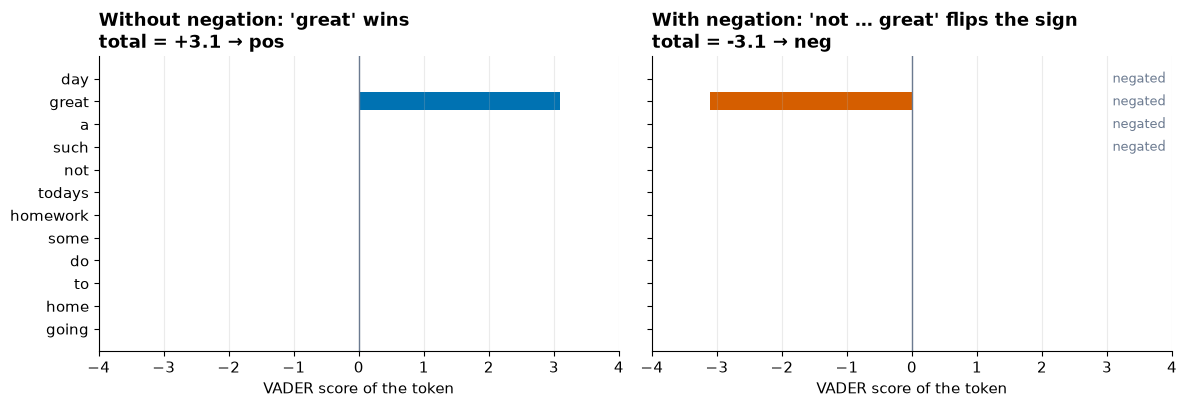

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, col, total, title in [(axes[0], table_plain["counts as"], score_plain, "Without negation: 'great' wins"),
                              (axes[1], table_neg["counts as"], score_neg, "With negation: 'not … great' flips the sign")]:
    y = np.arange(len(tokens))
    colours = [CLASS_COLORS["pos"] if v > 0 else CLASS_COLORS["neg"] if v < 0 else PALETTE["grey"] for v in col]
    ax.barh(y, col, color=colours)
    ax.axvline(0, color=PALETTE["grey"], lw=1)
    ax.set_yticks(y, tokens)
    ax.invert_yaxis()
    ax.set(xlim=(-4, 4), xlabel="VADER score of the token", title=f"{title}\ntotal = {total:+.1f} → {'pos' if total >= 0 else 'neg'}")
    ax.grid(axis="y", visible=False)
for i, negated in enumerate(table_neg["negated"]):
    if negated:
        axes[1].text(3.9, i, "negated", ha="right", va="center", fontsize=9, color=PALETTE["grey"])
fig.tight_layout()
plt.show()
save_slide(fig, "tm-lexicon-negation")

Only **one** of the 12 tokens is in the lexicon: *great* (+3.1). Without negation the tweet is "positive". With the rule, *not* flips the sign of every token after it until the end of the tweet (*such a great day*), so *great* counts −3.1 and the verdict becomes negative, which is correct. Notice also what the lexicon **cannot** see: *homework* is not a sentiment word in any dictionary, yet on Twitter it is a strong hint of a bad day.

Now the whole test set, four variants:

In [16]:
for name, lex in [("VADER", vader), ("AFINN", afinn)]:
    for negation in [False, True]:
        label = f"{name} lexicon" + (" + negation" if negation else "")
        t0 = time.perf_counter()
        pred = lexicon_predict(test["text"], lex, negation=negation)
        add_to_board(label, pred, "lexicon", time_s=time.perf_counter() - t0,
                     timing="live, CPU (clean + score; no training)")
print(f"Each lexicon scores the {len(test):,} test tweets in ≈ {board['AFINN lexicon']['time_s']:.2f} s (no training at all)")

coverage = test["clean"].map(lambda t: any(tok in vader for tok in tokenize(t))).mean()
print(f"Tweets with at least one VADER word: {coverage:.0%} → the other {1 - coverage:.0%} score 0 and are called 'pos'")
pd.DataFrame(board).T.drop(columns=["family", "timing"]).astype(float).round(3)

Each lexicon scores the 9,687 test tweets in ≈ 0.25 s (no training at all)
Tweets with at least one VADER word: 76% → the other 24% score 0 and are called 'pos'


,accuracy,macro_f1,recall_neg,time_s
Always 'pos' (baseline),0.831,0.454,0.000,NaN
VADER lexicon,0.806,0.648,0.405,0.257
VADER lexicon + negation,0.808,0.661,0.445,0.261
AFINN lexicon,0.809,0.651,0.403,0.246
AFINN lexicon + negation,0.812,0.665,0.440,0.300


The official **VADER** tool (`vaderSentiment` package) adds more rules on top of the word list: CAPITALS and `!!!` boost a score, *"but"* shifts weight to the second half, words like *"very"* intensify. Does it help?

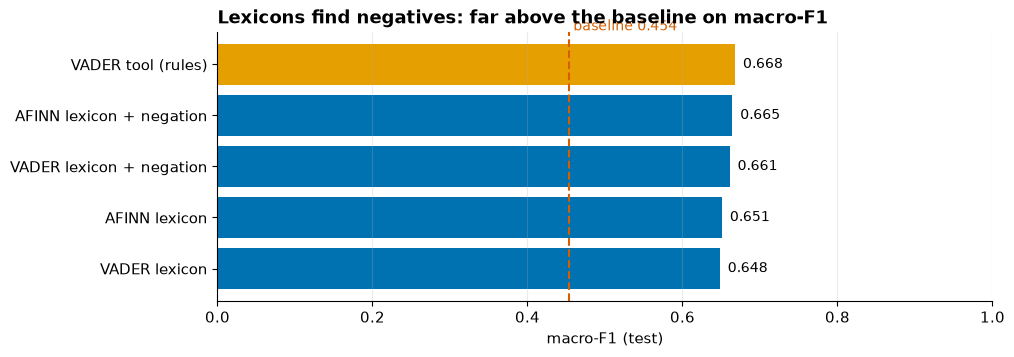

In [17]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()
t0 = time.perf_counter()
compound = test["text"].fillna("").map(lambda t: analyzer.polarity_scores(t)["compound"])
add_to_board("VADER tool (rules)", np.where(compound >= 0, "pos", "neg"), "lexicon",
             time_s=time.perf_counter() - t0, timing="live, CPU (score; no training)")
fig = show_board(highlight="VADER tool (rules)", title="Lexicons find negatives: far above the baseline on macro-F1")

Look at both numbers at once:

| | accuracy | macro-F1 | recall `neg` |
|---|---|---|---|
| Always `pos` | **0.83** | 0.45 | 0.00 |
| Best lexicon | ≈ 0.81 | **≈ 0.66** | ≈ 0.44 |

With **accuracy**, lexicons are *below* the baseline: every positive tweet they wrongly call negative costs more than the negatives they find. With **macro-F1**, they are far *above* it, because they actually catch ~44% of the negative tweets. Same predictions, opposite conclusions: **choosing the metric is choosing what "good" means.** The negation rule helps a bit (≈ +0.01).

### 💬 Discussion — Why do lexicons struggle with tweets?
Look at a few tweets they get wrong. What would a human use that the lexicon cannot?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

Main reasons, all visible in the errors: (1) **coverage**: about a quarter of the tweets contain no lexicon word, so they get score 0 and are called positive; (2) **context and sarcasm**: *"ain't it just awesome! You can take work everywhere… oh wait"*; (3) **domain words** whose sentiment depends on the topic (*sick*, *cold*, *work*, *homework*, *Monday*); (4) **sentiment without sentiment words**: *"No one want 2 play w/ me 2day"*. Lexicons are transparent and need no labels, which is great for a quick first look or when you have no labelled data, but a model that **learns from labelled examples** can discover that *homework* and *Monday* are negative on Twitter. That is the next section.
</details>

### ✏️ Exercise 1 — Move the lexicon's threshold (Difficulty ⭐)
Our rule says "score ≥ 0 → pos". Since most tweets with score 0 are positive anyway, what happens with a threshold of **0.5** or **−0.5** for `AFINN + negation`? Use `lexicon_predict(..., threshold=...)` and `evaluate`.

In [18]:
# TODO: try threshold = -0.5, 0, 0.5, 1 and compare macro-F1 and recall of neg

<details>
<summary>💡 Show solution</summary>

```python
for th in [-0.5, 0, 0.5, 1]:
    pred = lexicon_predict(test["text"], afinn, negation=True, threshold=th)
    print(th, {k: round(v, 3) for k, v in evaluate(test["class"], pred).items()})
```
AFINN scores are whole numbers, so −0.5 behaves like 0 and 0.5 like 1. A higher threshold calls more tweets negative: recall of `neg` jumps to ≈ 0.75 (every tweet with score 0 becomes negative!) but many positives are lost, so accuracy (≈ 0.59) and macro-F1 drop. The threshold is a knob, not a fix: the lexicon's information is the same. (Strictly, we should choose it on training data, not on the test set.)
</details>

<a id="sec-5"></a>
# 5. 🤖 Classic machine learning on TF-IDF

Now we let the data speak: **learn** which words matter from the 39,000 labelled training tweets.

**Representation:** TF-IDF like notebook 01, with three upgrades:
- our tweet tokenizer (keeps `USER`, `URL`, `#hashtags`, emoticons, `!` `?`, and *don't* as one token);
- **bigrams** (`ngram_range=(1, 2)`): *"not good"* becomes its own column, so the model can learn negation by itself;
- `min_df=2` (drop terms seen only once) and `sublinear_tf=True` (a word repeated 3 times is not 3× more important).

In [19]:
def make_tfidf(**overrides):
    """Our TF-IDF settings for tweets (pass e.g. max_features=5000 to change one of them)."""
    params = dict(tokenizer=tokenize, token_pattern=None, lowercase=False, ngram_range=(1, 2), min_df=2,
                  sublinear_tf=True)
    return TfidfVectorizer(**(params | overrides))

vectorizer = make_tfidf()
t0 = time.perf_counter()
X_train = vectorizer.fit_transform(train["clean"])      # learn vocabulary + IDF on train only
X_test = vectorizer.transform(test["clean"])
tfidf_s = time.perf_counter() - t0                     # counted in the time of every TF-IDF model
y_train = train["class"].to_numpy()
print(f"TF-IDF matrix: {X_train.shape[0]:,} tweets × {X_train.shape[1]:,} terms "
      f"({X_train.nnz / X_train.shape[0]:.0f} non-zero per tweet) in {tfidf_s:.1f} s")
print("Some bigrams:", [t for t in vectorizer.get_feature_names_out() if t.startswith("not ")][:12])

TF-IDF matrix: 39,152 tweets × 62,247 terms (23 non-zero per tweet) in 1.4 s
Some bigrams: ['not !', 'not ,', 'not .', 'not 2', 'not 5', 'not ?', 'not a', 'not able', 'not about', 'not actually', 'not afraid', 'not all']


> 🧠 **How it works: six classic models, in one line each** (you met most of them in Lesson 02)
>
> | Model | What it does with the TF-IDF columns | Good at | Weak at |
> |---|---|---|---|
> | **Multinomial Naive Bayes** | adds up the "evidence" of each word per class (notebook 01) | very fast, small data | probabilities too extreme |
> | **Logistic Regression** | one weight per word/bigram, summed and squashed into a probability | strong, fast, interpretable | only straight boundaries |
> | **Linear SVM** (`LinearSVC`) | also one weight per term, but maximises the *margin* between classes | text classification classic | no probabilities |
> | **K-Nearest Neighbours** | finds the K most similar training tweets (cosine) and lets them vote | simple, no training | slow at prediction, struggles in 60,000 dimensions |
> | **Random Forest** | hundreds of decision trees, each asking "does the tweet contain *sad*?" | non-linear patterns | sparse text with many columns |
> | **XGBoost** | trees built one after the other, each fixing the previous errors | tabular champion | slow on wide sparse text |
>
> 🧮 **Imbalance:** where a model supports it we ask it to **care equally about both classes** (`class_weight="balanced"` or XGBoost's `scale_pos_weight`): a mistake on a rare negative tweet then costs as much as ~5 mistakes on positive ones. Section 6 shows the effect.
>
> ⏱️ **CPU budget:** trees are slow on 60,000+ sparse columns, so Random Forest and XGBoost use the **5,000 most frequent terms** (same tweets, fewer columns). We say so on the leaderboard.

In [20]:
def fit_and_score(name, model, X_tr, X_te, y_tr=y_train, family="classic ML", prep_s=0.0,
                  timing="live, CPU (features + train + predict)"):
    """Train, predict the test set and add the result to the leaderboard.

    Time = prep_s (building the features) + training + predicting, so every model is timed the same way.
    """
    t0 = time.perf_counter()
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    seconds = prep_s + time.perf_counter() - t0
    if np.issubdtype(pred.dtype, np.number):           # XGBoost predicts 0/1 → back to "neg"/"pos"
        pred = np.where(pred == 1, "pos", "neg")
    scores = add_to_board(name, pred, family, time_s=seconds, timing=timing)
    print(f"{name:42s} macro-F1 {scores['macro_f1']:.3f} · recall neg {scores['recall_neg']:.3f} · {seconds:5.1f} s")
    return model

nb = fit_and_score("Naive Bayes · TF-IDF", MultinomialNB(alpha=0.1), X_train, X_test, prep_s=tfidf_s)
logreg = fit_and_score("LogReg balanced · TF-IDF",
                       LogisticRegression(C=4, class_weight="balanced", max_iter=2000), X_train, X_test,
                       prep_s=tfidf_s)
svm = fit_and_score("Linear SVM balanced · TF-IDF",
                    LinearSVC(C=0.5, class_weight="balanced", max_iter=5000, random_state=SEED), X_train, X_test,
                    prep_s=tfidf_s)
knn = fit_and_score("KNN (k=15, cosine) · TF-IDF",
                    KNeighborsClassifier(n_neighbors=15, metric="cosine", weights="distance", n_jobs=-1),
                    X_train, X_test, prep_s=tfidf_s)

Naive Bayes · TF-IDF                       macro-F1 0.640 · recall neg 0.238 ·   1.4 s


LogReg balanced · TF-IDF                   macro-F1 0.716 · recall neg 0.617 ·   1.6 s


Linear SVM balanced · TF-IDF               macro-F1 0.717 · recall neg 0.604 ·   1.8 s


KNN (k=15, cosine) · TF-IDF                macro-F1 0.613 · recall neg 0.195 ·   5.2 s


`LinearSVC` printed no `ConvergenceWarning`: with TF-IDF rows already scaled to length 1 and `max_iter=5000` it converges (if you ever see that warning, raise `max_iter` or lower `C`). Now the two tree ensembles, on the 5,000 most frequent terms:

In [21]:
t0 = time.perf_counter()
small_vec = make_tfidf(max_features=5000)
X_train_small = small_vec.fit_transform(train["clean"])
X_test_small = small_vec.transform(test["clean"])
small_s = time.perf_counter() - t0
y_train01 = (y_train == "pos").astype(int)             # XGBoost wants 0/1 labels
neg_per_pos = (y_train01 == 0).sum() / (y_train01 == 1).sum()

forest = fit_and_score("Random Forest balanced · 5k terms",
                       RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight="balanced_subsample",
                                              n_jobs=-1, random_state=SEED), X_train_small, X_test_small,
                       prep_s=small_s)
xgb = fit_and_score("XGBoost weighted · 5k terms",
                    XGBClassifier(n_estimators=300, learning_rate=0.2, max_depth=6, scale_pos_weight=neg_per_pos,
                                  tree_method="hist", n_jobs=-1, random_state=SEED),
                    X_train_small, X_test_small, y_tr=y_train01, prep_s=small_s)

Random Forest balanced · 5k terms          macro-F1 0.682 · recall neg 0.398 ·   7.9 s


XGBoost weighted · 5k terms                macro-F1 0.682 · recall neg 0.650 ·  20.5 s


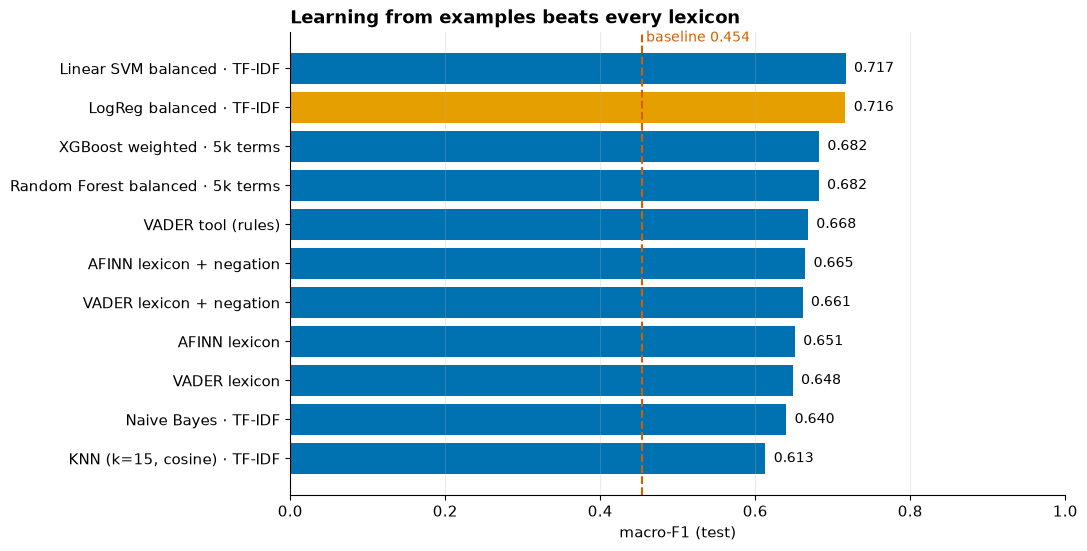

In [22]:
fig = show_board(highlight="LogReg balanced · TF-IDF", title="Learning from examples beats every lexicon")

**What we see:**
- The two **linear models** (Logistic Regression, linear SVM) lead, and train in about a second (building the TF-IDF features takes a few seconds more). On sparse text with tens of thousands of columns, linear models are hard to beat.
- **Naive Bayes** is fast but too shy with negatives (low recall of `neg`): it has no class weights.
- **KNN** suffers from the *curse of dimensionality*: in 60,000 dimensions almost every tweet is "far" from every other.
- **Random Forest** and **XGBoost** are the champions of *tables* (Lesson 02), but on wide sparse text they are slower and not better.

### 🔍 What did Logistic Regression learn?
One weight per term: positive → `pos`, negative → `neg`. Note the **bigrams** and the negation words.

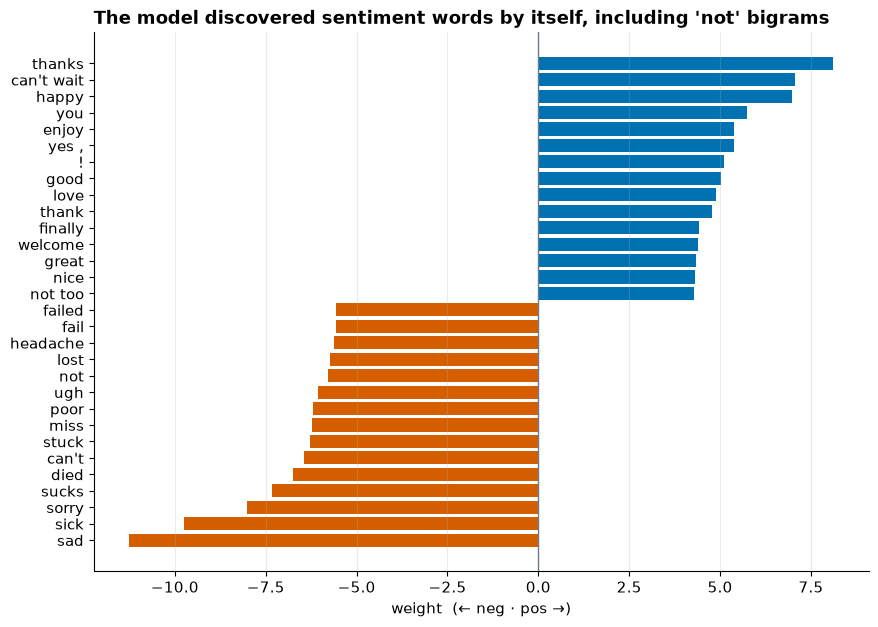

In [23]:
top = top_coefficients(vectorizer, logreg, n=15).sort_values("weight")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top["word"], top["weight"], color=[CLASS_COLORS[c] for c in top["towards"]])
ax.axvline(0, color=PALETTE["grey"], lw=1)
ax.set(xlabel="weight  (← neg · pos →)", title="The model discovered sentiment words by itself, including 'not' bigrams")
ax.grid(axis="y", visible=False)
plt.show()

Nobody told the model that *sad*, *miss*, *sucks* or *wish* are negative, or that *thanks* and *:)* (when present) are positive: it learned it from labels. It also learned **Twitter-specific** negatives that no general lexicon has.

### 🌉 A bridge to transformers: sentence embeddings
TF-IDF knows **words**, not **meaning**: *"I'm gutted"* and *"I'm so sad"* share no column. A **sentence embedding** model (here `all-MiniLM-L6-v2`, a small transformer, 22 M parameters) turns a whole sentence into **384 numbers** such that sentences with similar meaning get similar vectors. We then train the same Logistic Regression on those 384 columns.

⏱️ Encoding is the slow part on CPU (≈ 300 tweets/s), so we encode **10,000** training tweets plus the test set, and **cache** the vectors in `data/_cache/` so a second run is instant (and works offline: the model is only downloaded when there is no cache). For a fair comparison we also train TF-IDF + Logistic Regression on **the same 10,000 tweets**, with a TF-IDF fitted on those tweets only.

In [24]:
emb_sample = train.sample(10_000, random_state=SEED)
y_sample = emb_sample["class"].to_numpy()
cache = cache_dir() / "tweets_minilm_v2.npz"
DEMO = ["I am gutted", "I feel so sad", "The bus leaves at 9"]

E_train = None
if cache.exists():                       # 1) cached vectors: no model, no download needed
    stored = np.load(cache)
    E_train, E_test, sims = stored["train"], stored["test"], stored["demo_sims"]
    encode_s, encode_device = float(stored["seconds"]), str(stored["device"])
    emb_timing = f"cached: encoding measured once ({encode_s:.0f} s on {encode_device}) + live train/predict"
    emb_tag = f"encoding cached, {encode_device}"
else:                                    # 2) first run: download the model (≈ 90 MB) and encode
    try:
        from sentence_transformers import SentenceTransformer
        encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)
        t0 = time.perf_counter()
        E_train = encoder.encode(emb_sample["clean"].tolist(), batch_size=128, show_progress_bar=False)
        E_test = encoder.encode(test["clean"].tolist(), batch_size=128, show_progress_bar=False)
        encode_s, encode_device = time.perf_counter() - t0, DEVICE
        demo = encoder.encode(DEMO)
        sims = encoder.similarity(demo[:1], demo[1:])[0].numpy()
        np.savez_compressed(cache, train=E_train, test=E_test, demo_sims=sims, seconds=encode_s, device=DEVICE)
        emb_timing = f"live, {DEVICE} (encode + train + predict)"
        emb_tag = f"live {DEVICE}"
    except Exception as err:             # no internet and no cache: skip this part, the rest still works
        print(f"⚠️ Skipping the embeddings: could not load the MiniLM model ({type(err).__name__}). "
              "Connect to the internet and re-run this cell to try it.")

if E_train is not None:
    print(f"Embeddings: train {E_train.shape}, test {E_test.shape} · encoding took {encode_s:.0f} s on {encode_device}")
    print(f"'{DEMO[0]}' vs '{DEMO[1]}': {float(sims[0]):.2f} (no shared word!) · vs '{DEMO[2]}': {float(sims[1]):.2f}")
    emb_lr = fit_and_score("LogReg balanced · MiniLM embeddings (10k)",
                           LogisticRegression(C=1, class_weight="balanced", max_iter=2000),
                           E_train, E_test, y_tr=y_sample, family="embeddings", prep_s=encode_s, timing=emb_timing)

# Same budget for TF-IDF: vocabulary and IDF learned from the same 10,000 tweets only
t0 = time.perf_counter()
vec_10k = make_tfidf()
X_train_10k = vec_10k.fit_transform(emb_sample["clean"])
X_test_10k = vec_10k.transform(test["clean"])
same_10k = fit_and_score("LogReg balanced · TF-IDF (same 10k)",
                         LogisticRegression(C=4, class_weight="balanced", max_iter=2000),
                         X_train_10k, X_test_10k, y_tr=y_sample, prep_s=time.perf_counter() - t0)

Embeddings: train (10000, 384), test (9687, 384) · encoding took 90 s on cpu
'I am gutted' vs 'I feel so sad': 0.33 (no shared word!) · vs 'The bus leaves at 9': 0.07
LogReg balanced · MiniLM embeddings (10k)  macro-F1 0.673 · recall neg 0.716 ·  90.4 s


LogReg balanced · TF-IDF (same 10k)        macro-F1 0.693 · recall neg 0.543 ·   0.8 s


A surprise worth understanding: the embeddings are **not** better than TF-IDF on the same 10,000 tweets. Why? `all-MiniLM-L6-v2` was trained to put sentences **about the same topic** close together (great for search, notebook 05), not to separate *happy* from *sad*: *"I love Mondays"* and *"I hate Mondays"* are about the same thing! General meaning ≠ sentiment. To get sentiment we need a transformer that was **trained on sentiment**: section 7.

### ✏️ Exercise 2 — Unigrams only (Difficulty ⭐⭐)
Train the same balanced Logistic Regression with `ngram_range=(1, 1)` (words only, no bigrams). How much macro-F1 do the bigrams bring? Look at `"not " ` terms in the vocabulary: why can't a unigram model learn *"not good"*?

In [25]:
# TODO: a unigram TF-IDF + LogisticRegression(C=4, class_weight="balanced", max_iter=2000)

<details>
<summary>💡 Show solution</summary>

```python
uni = TfidfVectorizer(tokenizer=tokenize, token_pattern=None, lowercase=False, ngram_range=(1, 1), min_df=2, sublinear_tf=True)
model = LogisticRegression(C=4, class_weight="balanced", max_iter=2000).fit(uni.fit_transform(train["clean"]), y_train)
print({k: round(v, 3) for k, v in evaluate(test["class"], model.predict(uni.transform(test["clean"]))).items()})
print("vocabulary:", len(uni.vocabulary_), "vs", len(vectorizer.vocabulary_), "with bigrams")
```
Bigrams usually add about +0.01 to +0.02 macro-F1. A unigram model sees *not* and *good* as two separate, independent clues (*good* pushes towards positive whatever comes before it); the bigram *"not good"* is a new column that can get its own negative weight.
</details>

<a id="sec-6"></a>
# 6. 🎚️ Class weights and thresholds: catching more negatives

Remember Lesson 02: a classifier outputs a **probability**, and we choose the **threshold**. With 5× more positives than negatives, a plain model learns to say "pos" when in doubt. Two fixes:

1. **`class_weight="balanced"`**: during training, each negative tweet counts ≈ 5× more.
2. **Threshold tuning**: train normally, then call a tweet negative when P(pos) < *t*, with *t* chosen on **out-of-fold** predictions of the training set (5-fold `cross_val_predict`), never on the test set.

⚠️ For the out-of-fold predictions we cross-validate a **`Pipeline(TF-IDF → LogisticRegression)` on the raw text**, not the `X_train` matrix. `X_train`'s vocabulary and IDF were learned from *all* training tweets, including each held-out fold: a small leak. Inside the pipeline the TF-IDF is refitted on the four training folds every time (Lesson 02: everything that learns goes in the pipeline).

In [26]:
plain = LogisticRegression(C=4, max_iter=2000)
fit_and_score("LogReg plain · TF-IDF", plain, X_train, X_test, prep_s=tfidf_s)

t0 = time.perf_counter()
oof_model = make_pipeline(make_tfidf(), LogisticRegression(C=4, max_iter=2000))   # TF-IDF refitted in every fold
oof = cross_val_predict(oof_model, train["clean"], y_train, cv=5, method="predict_proba")[:, 1]
oof_s = time.perf_counter() - t0
thresholds = np.round(np.arange(0.40, 0.96, 0.01), 2)
curve = pd.DataFrame([evaluate(y_train, np.where(oof >= t, "pos", "neg")) | {"threshold": t} for t in thresholds])
best_t = float(curve.loc[curve["macro_f1"].idxmax(), "threshold"])
print(f"5-fold out-of-fold probabilities in {oof_s:.1f} s · best threshold for macro-F1: {best_t}")

p_test = plain.predict_proba(X_test)[:, 1]
add_to_board("LogReg plain + tuned threshold", np.where(p_test >= best_t, "pos", "neg"), "classic ML",
             time_s=board["LogReg plain · TF-IDF"]["time_s"] + oof_s,
             timing="live, CPU (features + 5-fold threshold search + train + predict)")
pd.DataFrame(board).T.loc[["LogReg plain · TF-IDF", "LogReg balanced · TF-IDF", "LogReg plain + tuned threshold"],
                          ["accuracy", "macro_f1", "recall_neg"]].astype(float).round(3)

LogReg plain · TF-IDF                      macro-F1 0.692 · recall neg 0.343 ·   2.2 s


5-fold out-of-fold probabilities in 8.8 s · best threshold for macro-F1: 0.69


,accuracy,macro_f1,recall_neg
LogReg plain · TF-IDF,0.865,0.692,0.343
LogReg balanced · TF-IDF,0.824,0.716,0.617
LogReg plain + tuned threshold,0.848,0.726,0.538


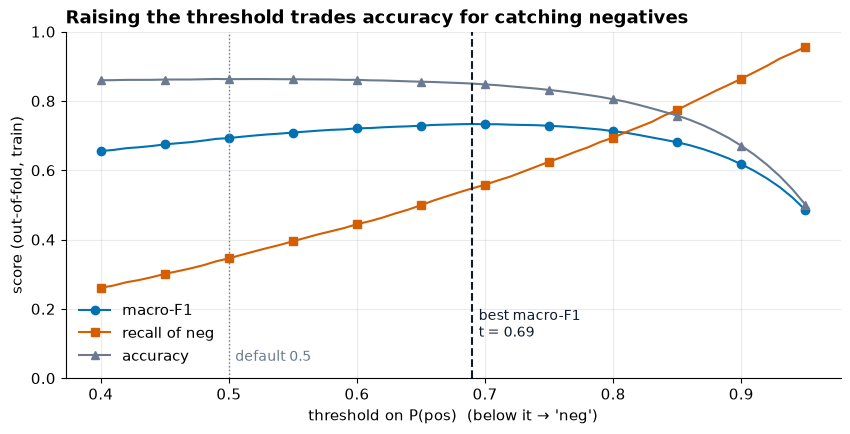

In [27]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for metric, marker, colour, label in [("macro_f1", "o", PALETTE["blue"], "macro-F1"),
                                      ("recall_neg", "s", CLASS_COLORS["neg"], "recall of neg"),
                                      ("accuracy", "^", PALETTE["grey"], "accuracy")]:
    ax.plot(curve["threshold"], curve[metric], marker=marker, markevery=5, ms=6, color=colour, label=label)
ax.axvline(0.5, color=PALETTE["grey"], ls=":", lw=1)
ax.text(0.505, 0.05, "default 0.5", color=PALETTE["grey"], fontsize=10)
ax.axvline(best_t, color=PALETTE["navy"], ls="--", lw=1.5)
ax.text(best_t + 0.005, 0.12, f"best macro-F1\nt = {best_t:.2f}", color=PALETTE["navy"], fontsize=10)
ax.set(xlabel="threshold on P(pos)  (below it → 'neg')", ylabel="score (out-of-fold, train)", ylim=(0, 1),
       title="Raising the threshold trades accuracy for catching negatives")
ax.legend(loc="lower left")
plt.show()
save_slide(fig, "tm-threshold")

Both fixes land in the same place: **recall of `neg` jumps from ≈ 0.34 to ≈ 0.54–0.62** while macro-F1 improves. Accuracy goes *down* a little, and that is fine: we now find almost twice as many angry customers. The threshold is a **business decision** (how many false alarms can the support team handle?), not a property of the model.

### ✏️ Exercise 3 — A support team that must not miss complaints (Difficulty ⭐⭐)
The brand asks: *"catch at least 75% of the negative tweets"*. Using the out-of-fold `curve`, find the **lowest** threshold that gives `recall_neg ≥ 0.75`, apply it to `p_test`, and report the test metrics. What is the price in accuracy?

In [28]:
# TODO: choose the threshold from `curve`, then evaluate on the test set

<details>
<summary>💡 Show solution</summary>

```python
t75 = float(curve.loc[curve["recall_neg"] >= 0.75, "threshold"].min())
print("threshold:", t75)
print({k: round(v, 3) for k, v in evaluate(test["class"], np.where(p_test >= t75, "pos", "neg")).items()})
```
The threshold moves up to ≈ 0.8–0.85: the model now calls "negative" any tweet it is not quite sure is positive. Recall of `neg` reaches ≈ 0.75 on the test set too (the out-of-fold estimate transfers well), but accuracy drops to ≈ 0.75–0.8: many positive tweets are now flagged. Whether that is acceptable depends on how many tweets a human can check per day.
</details>

<a id="sec-7"></a>
# 7. 🤗 Transformers: pretrained and fine-tuned

> 🧠 **How it works: transformers for text, in plain words**
> - **Idea:** instead of counting words, read them **in context**. In *"not such a great day"* the vector for *great* is changed by *not*; in *"this phone is sick"* *sick* means something else than in *"I feel sick"*.
> - **Pre-training:** a big model reads billions of sentences and learns to fill in missing words. It gets a general "feeling" for language. Expensive, done once by a lab.
> - **Fine-tuning:** we take that model, add a small classification layer on top, and train **everything a little bit** on our labelled tweets. Cheap compared with pre-training (minutes on a GPU), and it uses the PyTorch training loop you know from Lesson 02 (`AdamW`, epochs, validation).
> - **Analogy:** pre-training = years of school learning to read; fine-tuning = a two-day course to become a customer-support reader.
> - **Limits:** much slower than TF-IDF + LogReg, needs a GPU to train comfortably, harder to explain.
>
> 📖 **Mini-glossary:** **token / tokenizer** (a transformer cuts words into sub-word pieces: *"homework"* → *home* + *##work*) · **checkpoint** (a saved model you can download) · **logits** (raw scores before the softmax turns them into probabilities) · **epoch** (one pass over the training data).

### 7.1 A model already trained on tweets: `cardiffnlp/twitter-roberta-base-sentiment-latest`
A RoBERTa-base model (125 M parameters) pre-trained on **124 million tweets** (2018–2021) and fine-tuned for sentiment on the TweetEval benchmark by Cardiff NLP. We use it **as is**, without training anything: zero lines of training code.

It has **3 classes** (negative, neutral, positive) but our data has 2. Mapping rule: `neg` if *negative* is the most probable class, otherwise `pos` (neutral → `pos`, because in our data 5 in 6 tweets are positive and neutral-sounding tweets are mostly labelled positive).

⏱️ On a laptop CPU it reads ≈ 50–80 tweets per second (with length-sorted batches), so the whole test set takes ≈ 2–3.5 minutes. We run it **live on 500 tweets** to see it work and measure its speed, and load the predictions for the full test set that we computed with the exact same code on a GPU (`results/roberta_test_probs.csv`). If the model cannot be downloaded (no internet), the notebook says so and carries on with those shipped predictions.

In [29]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

ROBERTA = "cardiffnlp/twitter-roberta-base-sentiment-latest"
SHIPPED = RESULTS / "roberta_test_probs.csv"      # full test set, computed once on a GPU
print("Shipped predictions available:", SHIPPED.exists())

def load_model(name):
    """Load a Hugging Face model: from the local cache if possible, otherwise download it (≈ 500 MB)."""
    for local_only in (True, False):
        try:
            tok = AutoTokenizer.from_pretrained(name, local_files_only=local_only)
            mod = AutoModelForSequenceClassification.from_pretrained(name, local_files_only=local_only)
            return tok, mod.to(DEVICE).eval()
        except Exception as err:
            last_error = err
    print(f"⚠️ Could not load {name} ({type(last_error).__name__}). "
          + ("We continue with the shipped predictions." if SHIPPED.exists() else "This section is skipped."))
    return None, None

rob_tokenizer, rob_model = load_model(ROBERTA)
if rob_model is not None:
    print(rob_model.config.id2label, f"· {sum(p.numel() for p in rob_model.parameters()) / 1e6:.0f} M parameters")

def for_roberta(texts):
    """The model was trained with '@user' and 'http' placeholders."""
    return [t.replace("USER", "@user").replace("URL", "http") for t in texts]

def predict_proba(model, tokenizer, texts, batch_size=64, max_length=64):
    """Class probabilities for a list of texts, in batches (sorted by length = less padding = faster)."""
    order = np.argsort([len(t) for t in texts])
    out = np.zeros((len(texts), model.config.num_labels), dtype=np.float32)
    with torch.inference_mode():
        for i in range(0, len(texts), batch_size):
            idx = order[i:i + batch_size]
            batch = tokenizer([texts[j] for j in idx], padding=True, truncation=True,
                              max_length=max_length, return_tensors="pt").to(model.device)
            out[idx] = model(**batch).logits.softmax(-1).float().cpu().numpy()
    return out

if rob_model is not None:
    print(np.round(predict_proba(rob_model, rob_tokenizer, for_roberta(["todays not such a great day",
                                                                         "thanks for the follow USER!"])), 3))

Shipped predictions available: True


{0: 'negative', 1: 'neutral', 2: 'positive'} · 125 M parameters
[[0.882 0.103 0.015]
 [0.004 0.019 0.977]]


In [30]:
sample = test.sample(500, random_state=SEED)
gpu_run = json.loads((RESULTS / "finetune_results.json").read_text(encoding="utf-8"))   # timings of the GPU run
P_rob = None

if rob_model is not None:                     # live speed test on 500 tweets
    t0 = time.perf_counter()
    P_live = predict_proba(rob_model, rob_tokenizer, for_roberta(sample["clean"].tolist()))
    rate = len(sample) / (time.perf_counter() - t0)
    rob_time, rob_tag = len(test) / rate, f"live {DEVICE}, 500 tweets extrapolated"
    print(f"Live on {DEVICE}: {rate:.0f} tweets/s → full test set ≈ {rob_time / 60:.1f} min")

if RUN_HEAVY and rob_model is not None:       # the full test set, live
    t0 = time.perf_counter()
    P_rob = predict_proba(rob_model, rob_tokenizer, for_roberta(test["clean"].tolist()))
    rob_time, rob_tag = time.perf_counter() - t0, f"live {DEVICE}, full test set"
elif SHIPPED.exists():                        # precomputed with the same function on a GPU
    pre = pd.read_csv(SHIPPED).set_index("tweet")
    P_rob = pre.loc[test["tweet"], ["p_neg", "p_neu", "p_pos"]].to_numpy()
    if rob_model is not None:
        same = np.abs(pre.loc[sample["tweet"]].to_numpy() - P_live).max()
        print(f"Shipped vs live on the 500-tweet sample: max difference {same:.3f} (same model, same answers)")
    else:                                     # no model here: use the time measured with the GPU run
        rob_time = gpu_run["pretrained_roberta"]["test_inference_time_s"]
        rob_tag = f"precomputed on {gpu_run['hardware']['device'].replace('NVIDIA GeForce ', '')}"

if P_rob is not None:
    rob_argmax = np.where(P_rob.argmax(axis=1) == 0, "neg", "pos")       # neutral → pos
    rob_negpos = np.where(P_rob[:, 0] > P_rob[:, 2], "neg", "pos")       # ignore neutral, compare neg vs pos
    display(pd.DataFrame({"neg if 'negative' is the top class": evaluate(test["class"], rob_argmax),
                          "neg if P(negative) > P(positive)": evaluate(test["class"], rob_negpos)}).T.round(3))

Live on cpu: 63 tweets/s → full test set ≈ 2.5 min
Shipped vs live on the 500-tweet sample: max difference 0.000 (same model, same answers)


,accuracy,macro_f1,recall_neg
neg if 'negative' is the top class,0.838,0.726,0.593
neg if P(negative) > P(positive),0.777,0.690,0.734


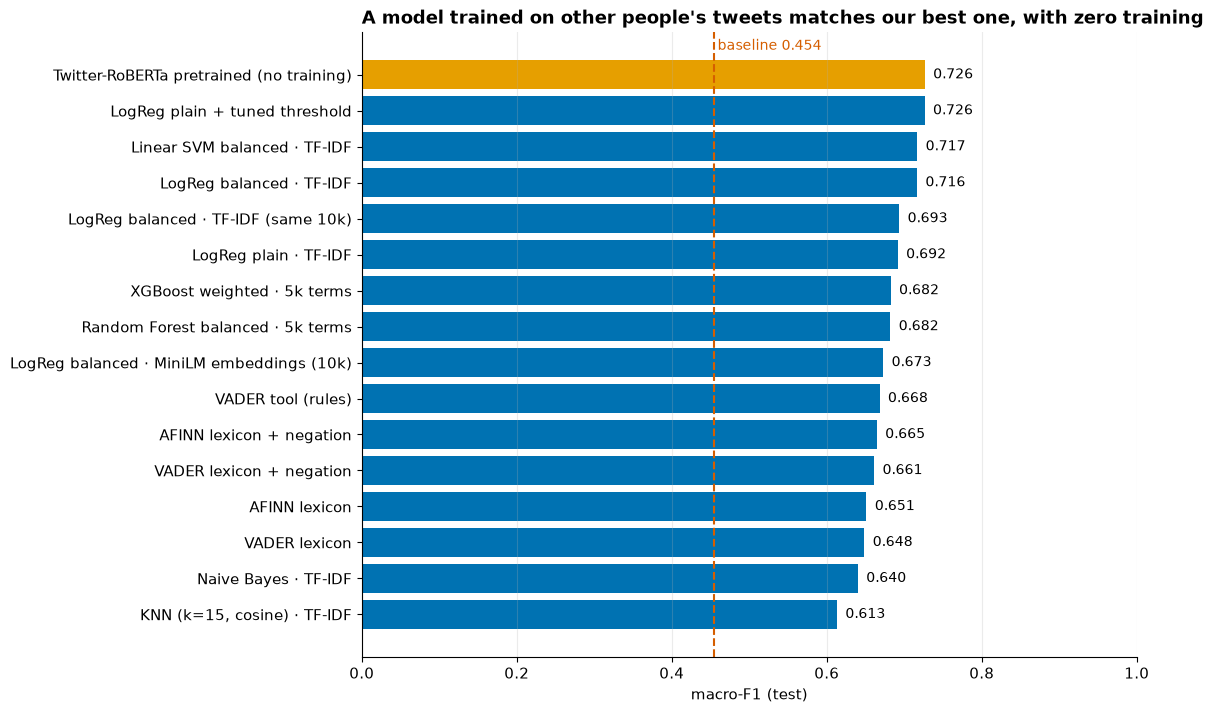

In [31]:
if P_rob is not None:
    add_to_board("Twitter-RoBERTa pretrained (no training)", rob_argmax, "transformer", time_s=rob_time,
                 timing=f"{rob_tag} (predict only; no training)")
    fig = show_board(highlight="Twitter-RoBERTa pretrained (no training)",
                     title="A model trained on other people's tweets matches our best one, with zero training")

**Without seeing a single one of our training tweets**, the pretrained model matches our best classic model (≈ 0.73 macro-F1), which needed 39,000 labelled tweets and a tuned threshold. It knows Twitter language from 124 M tweets. The second mapping rule (ignoring *neutral*) catches even more negatives but loses accuracy: again a threshold-like choice.

### 7.2 Fine-tuning DistilBERT on our tweets
`distilbert-base-uncased` (66 M parameters) is a smaller, faster version of BERT, pre-trained on books and Wikipedia, **not** on tweets and **not** on sentiment. We fine-tune it on our 35,000 training tweets (10% kept for validation) for 2 epochs with the Hugging Face `Trainer`, which runs the familiar loop for us: batches → forward → loss → backward → `AdamW` step, plus evaluation and mixed precision on GPU.

In [32]:
from sklearn.model_selection import train_test_split
from transformers import Trainer, TrainerCallback, TrainingArguments

CKPT = "distilbert/distilbert-base-uncased"
LABELS = {"neg": 0, "pos": 1}

def fine_tune_distilbert(train_df, epochs=2, batch_size=32, lr=5e-5, max_length=64):
    """Fine-tune DistilBERT on (clean text, class). Returns the trainer, the validation frame and the history."""
    tr_df, va_df = train_test_split(train_df, test_size=0.1, stratify=train_df["class"], random_state=SEED)
    tokenizer = AutoTokenizer.from_pretrained(CKPT)

    class TweetDataset(torch.utils.data.Dataset):
        def __init__(self, frame):
            self.enc = tokenizer(frame["clean"].tolist(), truncation=True, max_length=max_length)
            self.labels = frame["class"].map(LABELS).tolist()
        def __len__(self):
            return len(self.labels)
        def __getitem__(self, i):
            return {**{k: v[i] for k, v in self.enc.items()}, "labels": self.labels[i]}

    def compute_metrics(eval_pred):
        logits, labels = eval_pred
        return evaluate(np.where(labels == 1, "pos", "neg"), np.where(logits.argmax(-1) == 1, "pos", "neg"))

    class History(TrainerCallback):
        def __init__(self):
            self.rows = []
        def on_log(self, args, state, control, logs=None, **kwargs):
            self.rows.append({"step": state.global_step, "epoch": state.epoch, **(logs or {})})

    transformers.set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        CKPT, num_labels=2, id2label={0: "neg", 1: "pos"}, label2id=LABELS)
    steps_per_epoch = int(np.ceil(len(tr_df) / batch_size))
    args = TrainingArguments(
        output_dir=str(models_dir() / "distilbert-tweets"), num_train_epochs=epochs,
        per_device_train_batch_size=batch_size, per_device_eval_batch_size=128,
        learning_rate=lr, weight_decay=0.01, warmup_steps=int(0.06 * epochs * steps_per_epoch),
        eval_strategy="steps", eval_steps=steps_per_epoch // 4, logging_steps=steps_per_epoch // 4,
        save_strategy="no", fp16=torch.cuda.is_available(), report_to="none", disable_tqdm=True, seed=SEED)
    history = History()
    trainer = Trainer(model=model, args=args, train_dataset=TweetDataset(tr_df), eval_dataset=TweetDataset(va_df),
                      processing_class=tokenizer, compute_metrics=compute_metrics, callbacks=[history])
    trainer.train()
    return trainer, tokenizer, va_df, history.rows

In [33]:
if RUN_HEAVY:
    t0 = time.perf_counter()
    trainer, ft_tokenizer, va_df, rows = fine_tune_distilbert(train)
    train_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    p_ft = predict_proba(trainer.model.eval(), ft_tokenizer, test["clean"].tolist())[:, 1]
    predict_s = time.perf_counter() - t0
    train_log = [r for r in rows if "loss" in r]
    eval_log = [r for r in rows if "eval_loss" in r]
    ft = {"train_time_s": train_s, "test_inference_time_s": predict_s, "hardware": {"device": DEVICE},
          "history": {"epoch": [r["epoch"] for r in eval_log], "train_loss": [r["loss"] for r in train_log],
                      "eval_loss": [r["eval_loss"] for r in eval_log],
                      "eval_macro_f1": [r["eval_macro_f1"] for r in eval_log]}}
else:
    ft = json.loads((RESULTS / "finetune_results.json").read_text(encoding="utf-8"))
    p_ft = pd.read_csv(RESULTS / "distilbert_test_probs.csv").set_index("tweet").loc[test["tweet"], "p_pos"].to_numpy()
    print(f"Loaded precomputed run: {ft['hardware']['device']} · {ft['data']['train']:,} train / "
          f"{ft['data']['validation']:,} validation tweets · {ft['hyperparameters']['epochs']} epochs")
    print(f"Training time on the GPU: {ft['train_time_s'] / 60:.1f} min · "
          f"estimated on a laptop CPU: ≈ {ft['cpu_estimate']['train_time_s'] / 60:.0f} min")

ft_time = ft["train_time_s"] + ft["test_inference_time_s"]
ft_tag = f"live {DEVICE}" if RUN_HEAVY else f"precomputed on {ft['hardware']['device'].replace('NVIDIA GeForce ', '')}"
add_to_board("DistilBERT fine-tuned (2 epochs)", np.where(p_ft >= 0.5, "pos", "neg"), "transformer", time_s=ft_time,
             timing=f"{ft_tag} (train + predict)")

Loaded precomputed run: NVIDIA GeForce RTX 4060 Laptop GPU · 35,236 train / 3,916 validation tweets · 2 epochs
Training time on the GPU: 2.2 min · estimated on a laptop CPU: ≈ 33 min


accuracy        0.885
macro_f1        0.780
recall_neg      0.574
time_s        135.600
dtype: float64

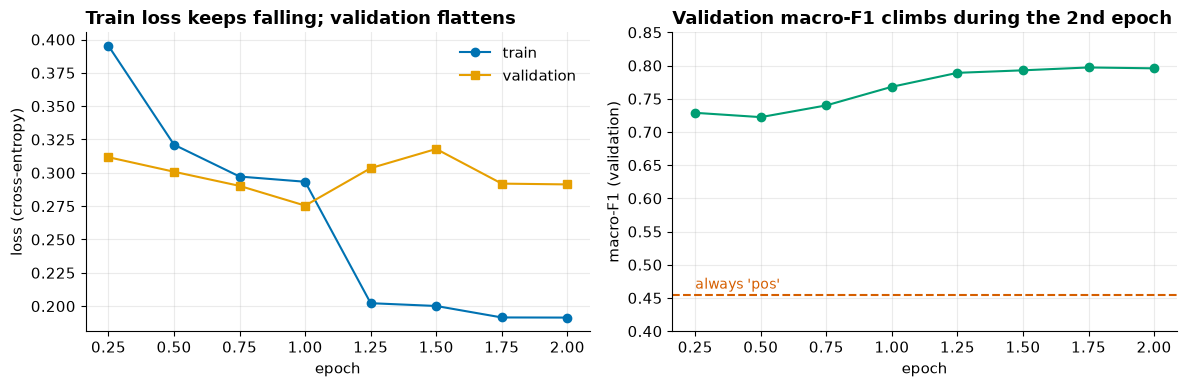

In [34]:
h = ft["history"]
n = min(len(h["train_loss"]), len(h["eval_loss"]))
epochs_axis = np.round(h["epoch"][:n], 2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_axis, h["train_loss"][:n], marker="o", label="train")
axes[0].plot(epochs_axis, h["eval_loss"][:n], marker="s", label="validation")
axes[0].set(xlabel="epoch", ylabel="loss (cross-entropy)", title="Train loss keeps falling; validation flattens")
axes[0].legend()
axes[1].plot(epochs_axis, h["eval_macro_f1"][:n], marker="o", color=PALETTE["green"])
axes[1].axhline(board[BASELINE]["macro_f1"], color=PALETTE["red"], ls="--", lw=1.5)
axes[1].text(epochs_axis[0], board[BASELINE]["macro_f1"] + 0.01, "always 'pos'", color=PALETTE["red"], fontsize=10)
axes[1].set(xlabel="epoch", ylabel="macro-F1 (validation)", ylim=(0.4, 0.85),
            title="Validation macro-F1 climbs during the 2nd epoch")
fig.tight_layout()
plt.show()
save_slide(fig, "tm-finetune-history")

Two epochs are enough: after one epoch the validation loss stops improving while the training loss keeps dropping (the start of **overfitting**, Lesson 02). With early stopping we would stop around here.

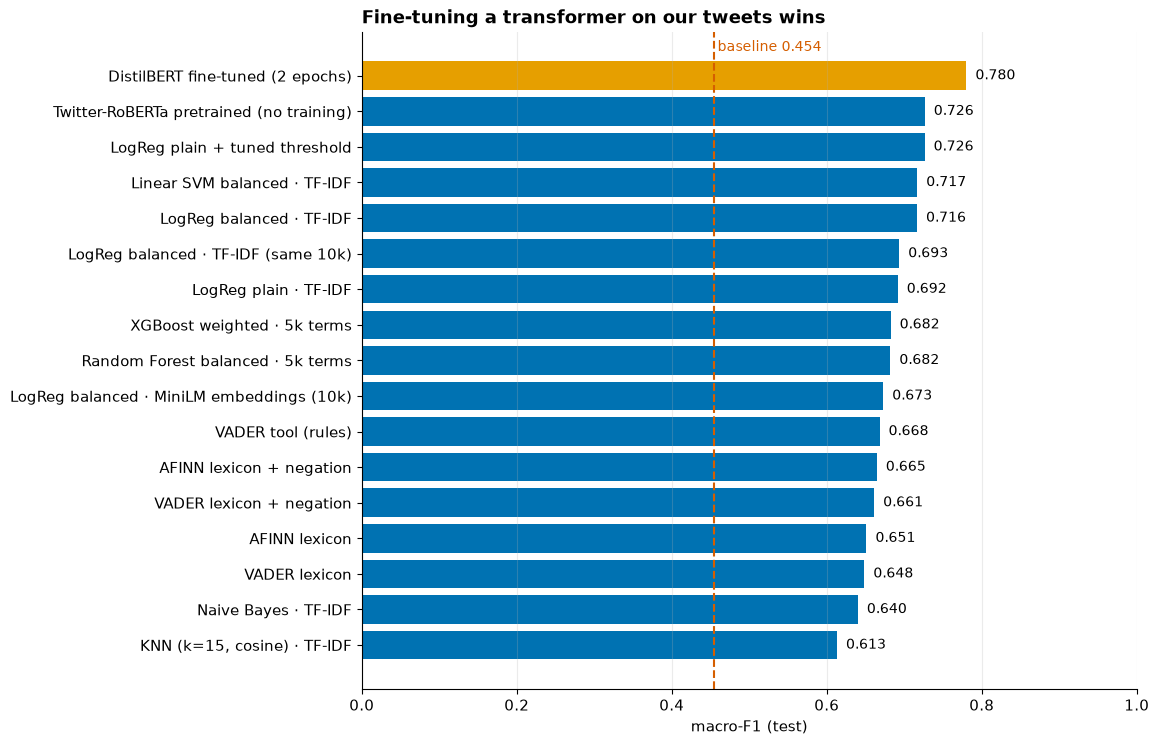

In [35]:
fig = show_board(highlight="DistilBERT fine-tuned (2 epochs)", title="Fine-tuning a transformer on our tweets wins")

<a id="sec-8"></a>
# 8. 🔬 Error analysis: the tweets every model gets wrong

A score is an average. To learn something we must **read the mistakes**. We take five very different models (a lexicon, two linear models, the pretrained and the fine-tuned transformer) and look for tweets that **all five** get wrong.

In [36]:
preds = pd.DataFrame({
    "AFINN + neg": lexicon_predict(test["text"], afinn, negation=True),
    "LogReg": logreg.predict(X_test),
    "Linear SVM": svm.predict(X_test),
    "DistilBERT": np.where(p_ft >= 0.5, "pos", "neg"),
}, index=test.index)
if P_rob is not None:
    preds["RoBERTa"] = rob_argmax
k = preds.shape[1]
wrong = preds.ne(test["class"], axis=0)
n_wrong = wrong.sum(axis=1)
print(f"How many of the {k} models are wrong, per tweet:")
print(n_wrong.value_counts().sort_index().rename("tweets").to_string())
all_wrong = test[n_wrong == k]
print(f"\n{len(all_wrong)} tweets ({len(all_wrong) / len(test):.1%}) fool all {k} models · "
      f"true class of those: {all_wrong['class'].value_counts().to_dict()}")
all_wrong.sample(12, random_state=1)[["text", "class"]]

How many of the 5 models are wrong, per tweet:
0    6358
1    1077
2    1023
3     520
4     343
5     366

366 tweets (3.8%) fool all 5 models · true class of those: {'neg': 283, 'pos': 83}


,text,class
6524,getting ready for school,neg
3329,Cub telly *shudder* I miss Mr Postgate more than ever,pos
6005,That's true.Happy for them in that respect.Hope they can keep it up.Saints had a GREAT season after Katrin...,neg
4202,Nooooooooooo! I thought you were gonna stay away from the dark side! Good luck,neg
4022,Snow when I wake up? And more paper writing URL,neg
7536,i want to give you a hug,neg
5388,what are your tweetwaster.com rankings people? I've got some serious climbing up to do!,neg
3739,Thats for you lily. It went over the limit when I tried to send it to yours.,neg
7172,I found something out: i suck at christmas wrapping,pos
205,yw poor little iPod Touch! She just wants to play online!,pos


Read them as a human. You will probably find:

- **Label noise**: tweets that honestly look positive but are labelled `neg` (or the opposite). If the labels came from removed emoticons, a *":("* after a neutral sentence made it negative. No model can recover information that was deleted.
- **Sarcasm and irony**: *"great, another Monday"*.
- **Context the tweet doesn't contain**: a reply to another tweet we cannot see.
- **Mixed feelings**: *"sad to leave, but what a week!"*.

> 💡 When the best models agree with each other and disagree with the label, check the label. Real projects often fix 1–5% of labels and gain more than with any new model.

### 💬 Discussion — Is 0.78 macro-F1 "good"?
What is the best score you think is possible on this dataset? How would you find out?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

The ceiling is **not 1.0**: some labels are noisy and some tweets are ambiguous even for humans. Ways to estimate it: ask 2–3 people to label the same 200 tweets and measure their agreement (inter-annotator agreement; for tweet sentiment it is often only 70–85%); look at what all strong models get wrong (as above). Above a certain point, a better **dataset** (clearer labels, more context) is worth more than a better model. Also link to business: for the brand, recall of `neg` at a fixed number of alerts per day may matter more than macro-F1.
</details>

<a id="sec-9"></a>
# 9. 🏁 Final leaderboard: score vs cost

,family,accuracy,macro_f1,recall_neg,time_s,timing
DistilBERT fine-tuned (2 epochs),transformer,0.885,0.780,0.574,135.6,precomputed on RTX 4060 Laptop GPU (train + predict)
Twitter-RoBERTa pretrained (no training),transformer,0.838,0.726,0.593,152.7,"live cpu, 500 tweets extrapolated (predict only; no training)"
LogReg plain + tuned threshold,classic ML,0.848,0.726,0.538,11.0,"live, CPU (features + 5-fold threshold search + train + predict)"
Linear SVM balanced · TF-IDF,classic ML,0.827,0.717,0.604,1.8,"live, CPU (features + train + predict)"
LogReg balanced · TF-IDF,classic ML,0.824,0.716,0.617,1.6,"live, CPU (features + train + predict)"
LogReg balanced · TF-IDF (same 10k),classic ML,0.816,0.693,0.543,0.8,"live, CPU (features + train + predict)"
LogReg plain · TF-IDF,classic ML,0.865,0.692,0.343,2.2,"live, CPU (features + train + predict)"
XGBoost weighted · 5k terms,classic ML,0.784,0.682,0.650,20.5,"live, CPU (features + train + predict)"
Random Forest balanced · 5k terms,classic ML,0.841,0.682,0.398,7.9,"live, CPU (features + train + predict)"
LogReg balanced · MiniLM embeddings (10k),embeddings,0.761,0.673,0.716,90.4,cached: encoding measured once (90 s on cpu) + live train/predict


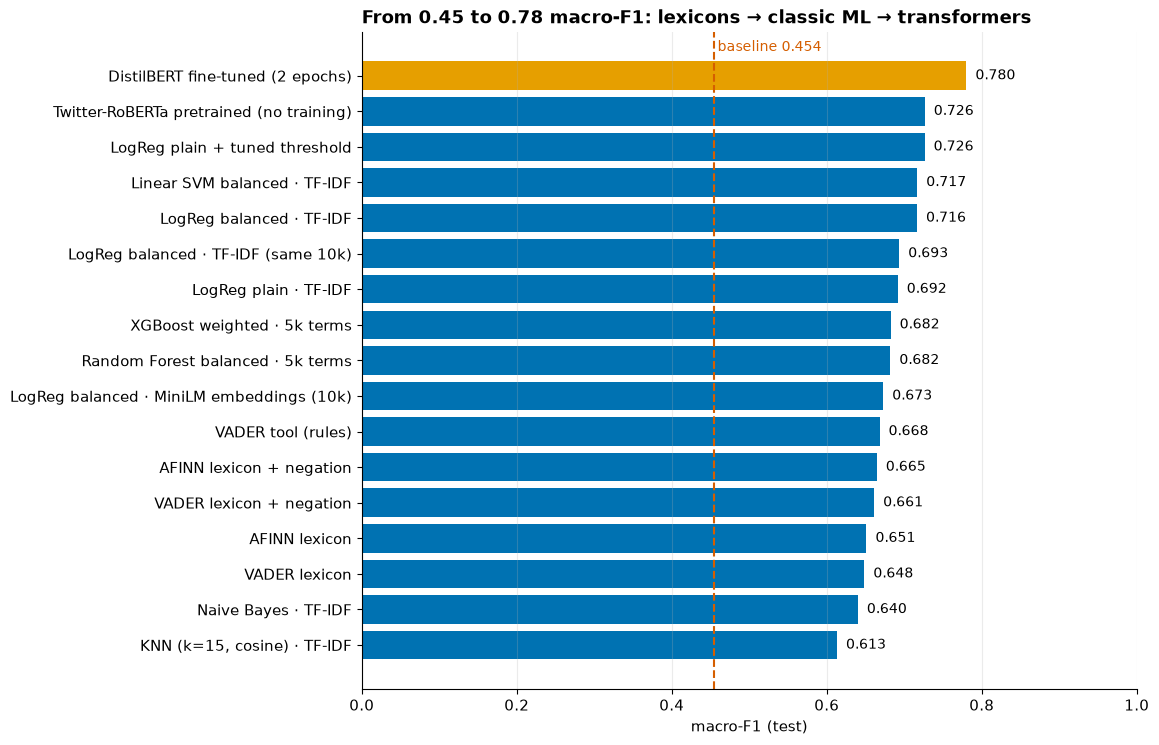

In [37]:
final = pd.DataFrame(board).T
final[["accuracy", "macro_f1", "recall_neg", "time_s"]] = final[["accuracy", "macro_f1", "recall_neg", "time_s"]].astype(float)
final = final.sort_values("macro_f1", ascending=False)
display(final.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}", "recall_neg": "{:.3f}", "time_s": "{:.1f}"},
                           na_rep="–")
        .background_gradient(subset=["macro_f1"], cmap="Purples", vmin=0.4, vmax=0.8))
fig = show_board(highlight="DistilBERT fine-tuned (2 epochs)",
                 title="From 0.45 to 0.78 macro-F1: lexicons → classic ML → transformers")
save_slide(fig, "tm-leaderboard")

`time_s` = seconds to **build the features, train and predict the whole test set**, the same recipe for every model (lexicons and the pretrained RoBERTa have nothing to train). The `timing` column says **where and how** each time was measured: live on this machine, cached, extrapolated from a sample, or precomputed on a GPU. Let's put score and cost on one picture, with the CPU estimate for DistilBERT too.

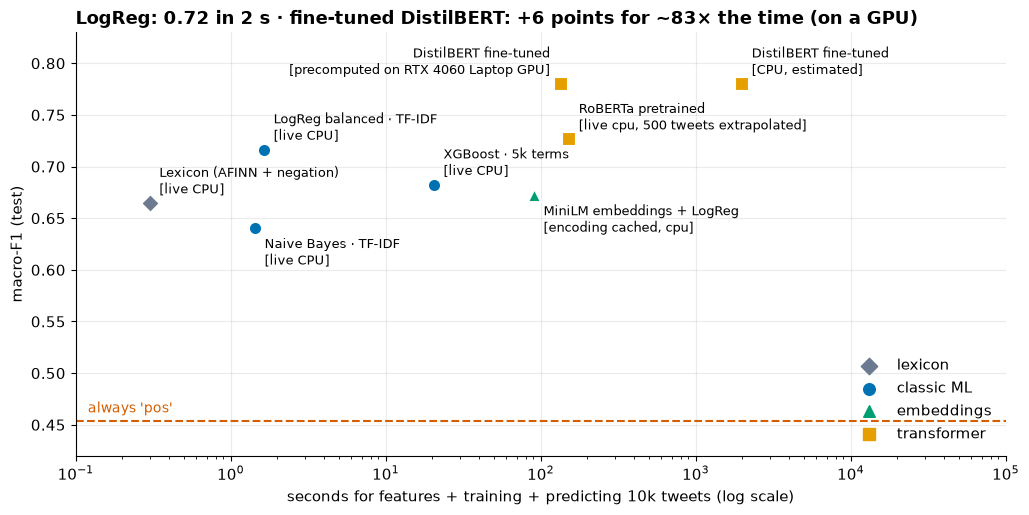

In [38]:
# (label on the plot, leaderboard entry, where the time comes from)
picks = [("Lexicon (AFINN + negation)", "AFINN lexicon + negation", "live CPU"),
         ("Naive Bayes · TF-IDF", "Naive Bayes · TF-IDF", "live CPU"),
         ("LogReg balanced · TF-IDF", "LogReg balanced · TF-IDF", "live CPU"),
         ("XGBoost · 5k terms", "XGBoost weighted · 5k terms", "live CPU"),
         ("MiniLM embeddings + LogReg", "LogReg balanced · MiniLM embeddings (10k)", globals().get("emb_tag", "")),
         ("RoBERTa pretrained", "Twitter-RoBERTa pretrained (no training)", globals().get("rob_tag", "")),
         ("DistilBERT fine-tuned", "DistilBERT fine-tuned (2 epochs)", ft_tag)]
cost = [(f"{label}\n[{tag}]", board[key]["time_s"], board[key]["macro_f1"], board[key]["family"])
        for label, key, tag in picks if key in board]
if "cpu_estimate" in ft and not RUN_HEAVY:
    cpu_s = ft["cpu_estimate"]["train_time_s"] + ft["test_inference_time_s"] * 10   # predicting ≈ 10× slower on CPU (RoBERTa: ≈ 11 s GPU vs ≈ 2 min CPU)
    cost.append(("DistilBERT fine-tuned\n[CPU, estimated]", cpu_s, board["DistilBERT fine-tuned (2 epochs)"]["macro_f1"],
                 "transformer"))

family_style = {"lexicon": (PALETTE["grey"], "D"), "classic ML": (PALETTE["blue"], "o"),
                "embeddings": (PALETTE["green"], "^"), "transformer": (PALETTE["orange"], "s")}
fig, ax = plt.subplots(figsize=(12, 5.5))
for name, seconds, score, family in cost:
    colour, marker = family_style[family]
    ax.scatter(seconds, score, s=90, color=colour, marker=marker, edgecolor="white", linewidth=1.5, zorder=3)
    if name.startswith(("Naive", "MiniLM")):                         # label below the point
        place = dict(xytext=(7, -6), ha="left", va="top")
    elif name.startswith("DistilBERT") and "estimated" not in name:  # label to the left
        place = dict(xytext=(-8, 4), ha="right", va="bottom")
    else:                                                            # label above, to the right
        place = dict(xytext=(7, 4), ha="left", va="bottom")
    ax.annotate(name, (seconds, score), textcoords="offset points", fontsize=9, **place)
for family, (colour, marker) in family_style.items():
    ax.scatter([], [], color=colour, marker=marker, s=70, label=family)
ax.axhline(board[BASELINE]["macro_f1"], color=PALETTE["red"], ls="--", lw=1.5)
ax.text(0.12, board[BASELINE]["macro_f1"] + 0.008, "always 'pos'", color=PALETTE["red"], fontsize=10)
lr, ft_row = board["LogReg balanced · TF-IDF"], board["DistilBERT fine-tuned (2 epochs)"]
ax.set_xscale("log")
ax.set(xlim=(0.1, 100000), ylim=(0.42, 0.83), xlabel="seconds for features + training + predicting 10k tweets (log scale)",
       ylabel="macro-F1 (test)",
       title=f"LogReg: {lr['macro_f1']:.2f} in {lr['time_s']:.0f} s · fine-tuned DistilBERT: "
             f"+{100 * (ft_row['macro_f1'] - lr['macro_f1']):.0f} points for ~{ft_row['time_s'] / lr['time_s']:.0f}× the time (on a GPU)")
ax.legend(loc="lower right")
plt.show()
save_slide(fig, "tm-cost-vs-score")

**How to choose?** There is no single winner, there is a **trade-off**:

| Option | Score | Cost | When to use it |
|---|---|---|---|
| Lexicon | low | ~0 (no training, no labels) | quick look, no labelled data, need to explain every decision |
| TF-IDF + Logistic Regression | good | a few seconds on a laptop (features + training) | strong baseline; millions of texts per hour on a CPU; readable weights |
| Pretrained transformer | as good as the best classic model, with zero labels | no training, but ~50–80 tweets/s on a laptop CPU | no labels but a model exists for your domain (tweets, reviews…) |
| Fine-tuned transformer | best | minutes on GPU, ~30 min on CPU; bigger to deploy | you have labels and a GPU, and the extra points matter |

> 🧭 **Rule of thumb:** always start with TF-IDF + Logistic Regression. Only move up if the gain is worth the cost **for your problem**.

### ✏️ Exercise 4 — Your own tweets against three models (Difficulty ⭐⭐)
Write 4–5 tweets of your own (sarcasm, negation, slang, emojis…) and compare `logreg` (with `vectorizer`), the pretrained RoBERTa and the AFINN lexicon. Which model do you trust most, and why?

In [39]:
my_tweets = ["not bad at all, I actually liked it",
             "Oh great, my flight is delayed again. Just perfect.",
             "this new phone is sick 🔥"]
# TODO: clean the tweets, then predict with logreg, RoBERTa (predict_proba + argmax rule) and the AFINN lexicon

<details>
<summary>💡 Show solution</summary>

```python
clean = [clean_tweet(t) for t in my_tweets]
P = predict_proba(rob_model, rob_tokenizer, for_roberta(clean))
pd.DataFrame({
    "tweet": my_tweets,
    "LogReg": logreg.predict(vectorizer.transform(clean)),
    "RoBERTa": np.where(P.argmax(axis=1) == 0, "neg", "pos"),
    "RoBERTa P(neg/neu/pos)": [np.round(p, 2) for p in P],
    "AFINN + neg": lexicon_predict(my_tweets, afinn, negation=True),
})
```
What we got: the **lexicon** gets *"not bad at all"* right (the negation rule flips *bad*), but is fooled by *"great"* and *"perfect"* in the sarcastic tweet and by the slang *"sick"*. **LogReg** calls all three negative: *not* and *bad* are both negative clues for it, and *sick* is a negative word on Twitter. **RoBERTa**, trained on millions of tweets, gets all three right, sarcasm included (P(neg) ≈ 0.85). Try your own: it is not always right, and its probabilities show its doubt.
</details>

### ✏️ Exercise 5 — Cheaper transformer predictions (Difficulty ⭐⭐⭐)
Prediction speed on CPU depends on how much text the model reads. Measure the live speed of RoBERTa on the same 500-tweet `sample` with `max_length=32` instead of 64 and with `batch_size=16` instead of 64. Do the predictions change? Which setting is faster on your machine?

In [40]:
# TODO: time predict_proba(rob_model, rob_tokenizer, ..., batch_size=..., max_length=...) and compare with P_live

<details>
<summary>💡 Show solution</summary>

```python
texts = for_roberta(sample["clean"].tolist())
for bs, ml in [(64, 64), (64, 32), (16, 64)]:
    t0 = time.perf_counter()
    P = predict_proba(rob_model, rob_tokenizer, texts, batch_size=bs, max_length=ml)
    s = time.perf_counter() - t0
    changed = (P.argmax(1) != P_live.argmax(1)).mean()
    print(f"batch {bs:3d}, max_length {ml}: {len(texts) / s:5.0f} tweets/s · predictions changed: {changed:.1%}")
```
Most tweets are shorter than 32 tokens, so `max_length=32` changes very few predictions (only long tweets get cut) and is a bit faster. Because we sort by length, batches have little padding, so the batch size matters less; on a CPU, medium batches are often the sweet spot. Measuring beats guessing.
</details>

<a id="sec-10"></a>
# 10. 📌 Summary

| Idea | In one line |
|---|---|
| Baseline & metric | "Always pos" = 83% accuracy but 0.45 macro-F1: on imbalanced data, use macro-F1 and recall of the minority |
| Cleaning | Remove empty texts and duplicates; **remove test texts seen in train** (leakage) |
| Text EDA | Distinctive words/bigrams per class, patterns (negations, `!`), and what is *missing* (emoticons) |
| Lexicons | Sum of word scores + negation rule: no training, transparent, limited by coverage and context |
| TF-IDF + linear models | Bigrams + Logistic Regression / linear SVM: fast, strong, interpretable |
| KNN, RF, XGBoost | Great on tables, weaker and slower on wide sparse text |
| Class weights / threshold | The same model catches ~2× more negatives with `class_weight` or a tuned threshold |
| Embeddings | Capture *topic/meaning*, not necessarily *sentiment* |
| Transformers | Read words in context; pretrained on tweets ≈ free gain; fine-tuned = best score, highest cost |
| Error analysis | Read the tweets all models miss: noise, sarcasm, missing context |

**✅ Checklist:**
- [ ] I measured the majority-class baseline with more than one metric.
- [ ] My test set has no duplicates of training texts.
- [ ] Vectoriser / threshold were fitted on training data only.
- [ ] I compared models on the **same** test set, with time as well as score.
- [ ] I read real errors before trusting the leaderboard.

<a id="sec-11"></a>
# 11. 📚 Learn more

> 📚 **Learn more**
> - Hutto & Gilbert (2014). [*VADER: A Parsimonious Rule-based Model for Sentiment Analysis of Social Media Text*](https://ojs.aaai.org/index.php/ICWSM/article/view/14550). ICWSM. · AFINN: [github.com/fnielsen/afinn](https://github.com/fnielsen/afinn)
> - Barbieri et al. (2020). [*TweetEval: Unified Benchmark and Comparative Evaluation for Tweet Classification*](https://arxiv.org/abs/2010.12421) · model card of [`cardiffnlp/twitter-roberta-base-sentiment-latest`](https://huggingface.co/cardiffnlp/twitter-roberta-base-sentiment-latest)
> - Hugging Face LLM Course, [chapter 3: Fine-tuning a pretrained model](https://huggingface.co/learn/llm-course/chapter3/1) · [Trainer documentation](https://huggingface.co/docs/transformers/main_classes/trainer)
> - Sanh et al. (2019). [*DistilBERT, a distilled version of BERT*](https://arxiv.org/abs/1910.01108)
> - Go, Bhayani & Huang (2009). *Twitter Sentiment Classification using Distant Supervision* (Sentiment140: emoticons as labels).
>
> 🤖 **Link to modern AI:** chat assistants are transformers too, much bigger, pre-trained the same way and then fine-tuned. The questions of this notebook (baseline, leakage, label noise, cost vs score) apply to them unchanged.

---
<div align="center">

⬅️ [Previous: 01 · Text Mining basics: SMS spam](../01_mini_project_sms_spam/01_Text_Mining_Basics_SMS_Spam.ipynb) &nbsp;·&nbsp; 🏠 [Lesson 03](../../README.md) &nbsp;·&nbsp; [Next: 🎮 Challenge 1 · Fool the sentiment model](../03_challenge_fool_the_model/Challenge_1_Fool_The_Sentiment_Model.ipynb) ➡️

After the challenge: [03 · Computer Vision basics: Fashion-MNIST](../../02_computer_vision/01_mini_project_fashion_mnist/03_Computer_Vision_Basics_Fashion_MNIST.ipynb)

**The AI Learning Hub** · Lesson 03 — Applied AI: unstructured data<br>
MIT License

</div>